This notebook computes the long range excitatory vs. inhibitory inputs to each node according to the SLN and structural connectome
and plots the net long range input vs. hierarchy and vs. NMDA receptor density, splits the nodes into excitation-receivers
and inhibition-receivers and plots the corresponding figures.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import pearsonr, zscore
from nibabel.freesurfer.io import read_annot
from nilearn import datasets, plotting
import matplotlib.patches as mpatches
import scienceplots
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
plt.style.use(['science', 'nature'])
plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.title_fontsize": 16,
    "legend.fontsize": 14,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)
colors = {
    "grey":   "#4d4d4d",
}
cmaps_fig2 = {
    "excitation_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#e7f6ed", "#86c3a2", "#56c68a"], N=256
    ),
    "inhibition_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#fee8c8", "#fdbb84", "#e69f00"], N=256
    )
}

## Load relevant data into a dataframe for ease of manipulation

In [12]:
# How much excitation / inhibition the nodes receive from other nodes
W_E = np.load('../../data/processed/schaefer100_W_E_SC_SLN.npy') # Matrix of SC * SLN
W_I = np.load('../../data/processed/schaefer100_W_I_SC_SLN.npy') # Matrix of SC * (1 - SLN)
E_to_source = np.zeros(50)
I_to_source = np.zeros(50)
for index, row in enumerate(W_E): # Each row represents a target, and each column a source
    E_to_source[index] = np.sum(row)
for index, row in enumerate(W_I): # Each row represents a target, and each column a source
    I_to_source[index] = np.sum(row)
E_minus_I_receive = E_to_source - I_to_source # Net excitation
# Area names, remove the 7Networks_LH_ prefix from names
area_names = pd.read_csv('../../data/processed/schaefer100_LH_area_names.csv')['Area_name'].tolist()
for index, name in enumerate(area_names):
    area_names[index] = name.replace('7Networks_LH_', '')
    
# Load hierarchy for left hemisphere
hierarchies = pd.read_csv('../../data/processed/schaefer100_LH_hierarchy.csv')['Hierarchy_val'].tolist()

W = np.array(pd.read_csv('../../data/processed/schaefer100_LH_sc.csv')) # DTI derived normalized structural connectivity matrix
N = W.shape[0] # Number of areas in the network

# Load NMDA receptor density based on autoradiography (initially nan values were filled through the relationship with hierarchy)
nmda_rd = pd.read_csv('../../data/processed/autorad_schaefer100_LH_NMDA_rd.csv')['NMDA_rd']

# Build dataframe with all the data
dict_network = {'area_names': area_names, 'hierarchy': hierarchies, 'E_to_source': E_to_source,
                'I_to_source': I_to_source, 'E_minus_I_receive': E_minus_I_receive,
                'nmda_rd': nmda_rd,}
network_connectivity = pd.DataFrame(dict_network)

## Plot W_E: matrix of long-range projections that target excitatory populations

In [13]:
network_connectivity_excitatory = network_connectivity['E_to_source'].tolist()

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_excitatory_input = np.full(labels.shape, np.nan)
for i in range(len(region_names)):
    if i == 0:
        mapped_excitatory_input[labels == i] = np.nan
    else:
        mapped_excitatory_input[labels == i] = network_connectivity_excitatory[i - 1]
vmin, vmax = np.nanmin(mapped_excitatory_input), np.nanmax(mapped_excitatory_input)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_excitatory_input, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps_fig2['excitation_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/long_rage_projections_strengths_schaefer100/W_E_matrix_{view}.{ext}', dpi=dpi, bbox_inches='tight')
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Plot W_I: matrix of long-range projections that target inhibitory populations

In [14]:
network_connectivity_inhibitory = network_connectivity['I_to_source'].tolist()

annot_path = ('../../data/raw/brain_annotations/Schaefer/fsaverage/'
               'atl-Schaefer2018_space-fsaverage_hemi-L_'
               'desc-100Parcels7Networks_deterministic.annot')
labels, ctab, region_names = read_annot(annot_path)

mapped_inhibitory_input = np.full(labels.shape, np.nan)
for i in range(len(region_names)):
    if i == 0:
        mapped_inhibitory_input[labels == i] = np.nan
    else:
        mapped_inhibitory_input[labels == i] = network_connectivity_inhibitory[i - 1]
vmin, vmax = np.nanmin(mapped_inhibitory_input), np.nanmax(mapped_inhibitory_input)

fs = datasets.fetch_surf_fsaverage('fsaverage')
for view in ['lateral','medial']:
    fig = plt.figure(constrained_layout=True, figsize=(6,6))
    ax = fig.add_subplot(1,1,1, projection='3d')
    plotting.plot_surf_stat_map(
        fs.infl_left, mapped_inhibitory_input, fs.sulc_left,
        hemi='left', view=view,
        cmap=cmaps_fig2['inhibition_seq'], colorbar=True,
        symmetric_cbar=False,
        vmin=vmin, vmax=vmax,
        axes=ax, figure=fig,
        engine='matplotlib', avg_method='median'
    )
    for ext in ['pdf']:
        dpi = 1200 if ext in ['png'] else None
        fig.savefig(f'../results/long_rage_projections_strengths_schaefer100/W_I_matrix_{view}.{ext}', dpi=dpi, bbox_inches='tight')
    plt.close()

[get_dataset_dir] Dataset found in /home/rad216/nilearn_data/fsaverage


## Plot long range input to excitatory vs. inhibitory popoulations and cluster based on position relative to x=y line

In [15]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})

Number of excitation receivers: 28


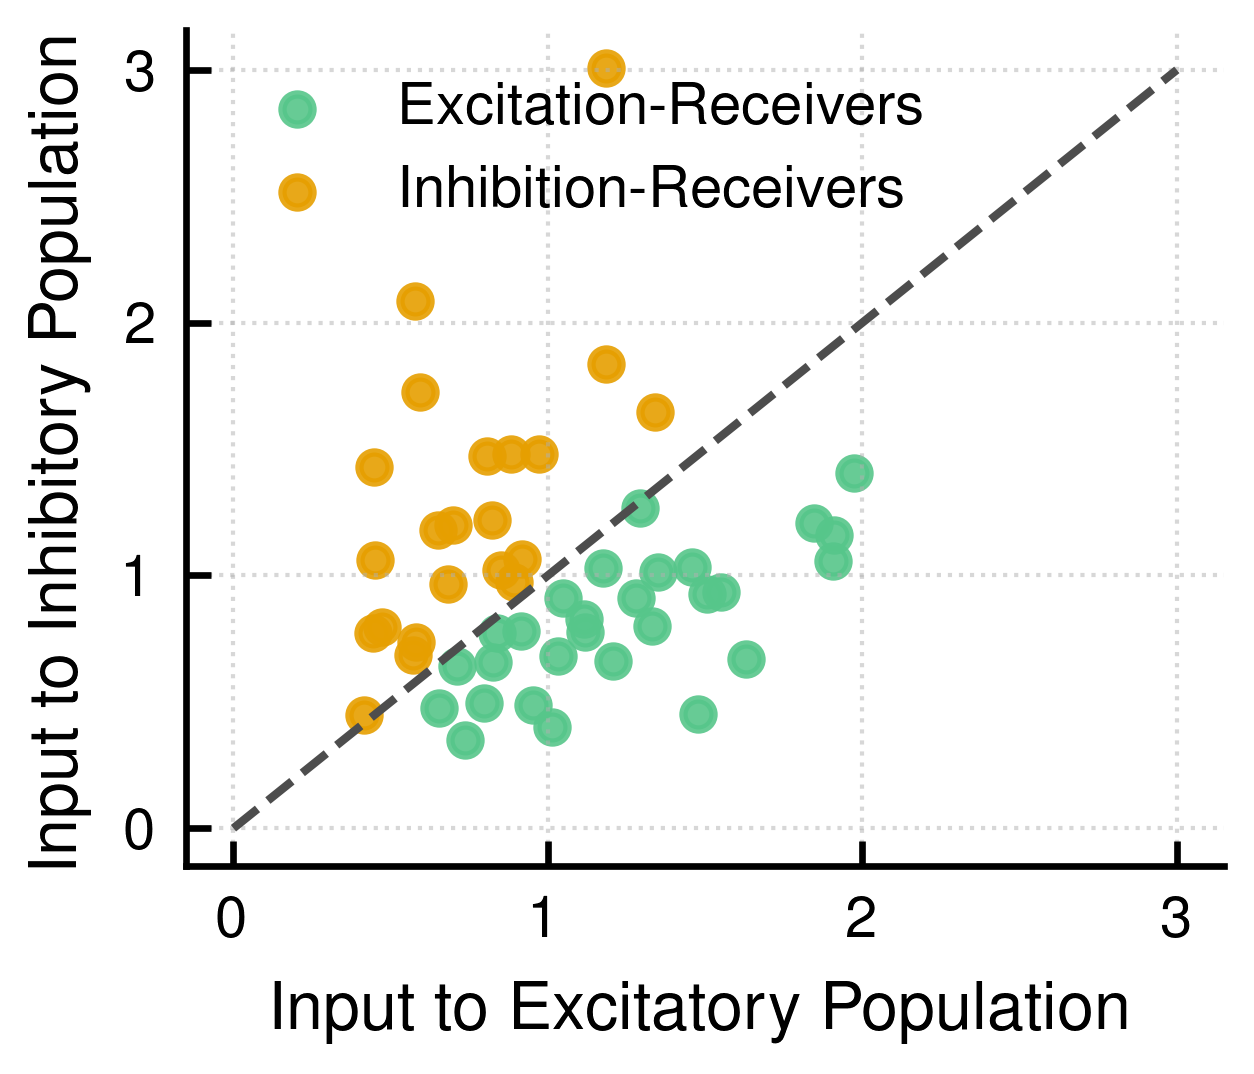

In [16]:
def excitation_inhibition_receivers(row):
    if row['E_to_source']  - row['I_to_source'] > 0:
        return 'Excitation-Receivers'
    else:
        return 'Inhibition-Receivers'

df_e_vs_i = network_connectivity.copy()
df_e_vs_i['node_type'] = df_e_vs_i.apply(excitation_inhibition_receivers, axis=1)
print("Number of excitation receivers:", len(df_e_vs_i[df_e_vs_i['node_type'] == 'Excitation-Receivers']))
# Figure 2
fig, ax = plt.subplots(figsize=(2.2, 1.9))
# Boolean masks
mask_exc = df_e_vs_i['E_to_source'] >= df_e_vs_i['I_to_source']
mask_inh = ~mask_exc
# plot excitation-receivers
ax.scatter(
    df_e_vs_i.loc[mask_exc, 'E_to_source'],
    df_e_vs_i.loc[mask_exc, 'I_to_source'],
    c='#56c68a',
    s=13,
    alpha=0.9,
    label='Excitation-Receivers'
)
# plot inhibition-receivers
ax.scatter(
    df_e_vs_i.loc[mask_inh, 'E_to_source'],
    df_e_vs_i.loc[mask_inh, 'I_to_source'],
    c='#e69f00',
    s=13,
    alpha=0.9,
    label='Inhibition-Receivers'
)
ax.plot([0, 3], [0, 3], color=colors['grey'], ls='--', lw=1.0)
ax.set_xlabel('Input to Excitatory Population', )
ax.set_ylabel('Input to Inhibitory Population', )
ax.grid(linestyle=':', alpha=0.5)
ax = plt.gca()
from matplotlib.ticker import MaxNLocator

ax.minorticks_off()
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))
ax.grid(which='major', linestyle=':', alpha=0.5)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
leg = ax.legend(loc='best', frameon=False)
frame = leg.get_frame()
frame.set_edgecolor('grey')
plt.tight_layout()
plt.savefig('../results/long_rage_projections_strengths_schaefer100/E_to_source_vs_I_to_source.svg', bbox_inches='tight')
plt.show()
plt.close()

## Plot net long range input (E minus I) vs. hierarchy

In [17]:
mpl.rcParams.update({
    "font.size": 6,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})

Hierarchy vs. net-E Pearson r = 0.796, p = 4.94e-12


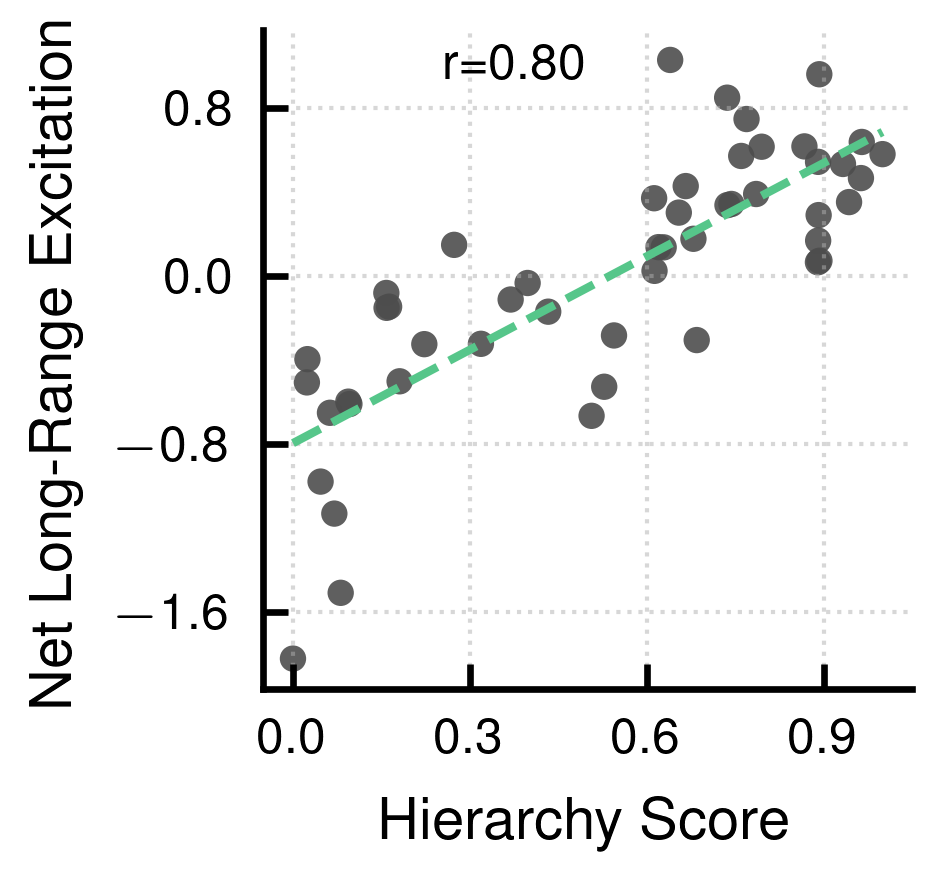

In [18]:
# Fit a simple linear trend line
x = df_e_vs_i['hierarchy']
y = df_e_vs_i['E_minus_I_receive']
slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept

r, p = pearsonr(x, y)
print(f"Hierarchy vs. net-E Pearson r = {r:.3f}, p = {p:.3g}")

# Figure 2
plt.figure(figsize=(1.65, 1.55))
plt.scatter(x, y, s=10, alpha=0.9, color='#4d4d4d', edgecolor='none')
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color="#56c68a", linestyle='--', linewidth=1,
         label=f"y = {slope:.2f} x hierarchy + ({intercept:.2f})")
plt.xlabel('Hierarchy Score', )
plt.ylabel('Net Long-Range Excitation', )
plt.grid(linestyle=':', alpha=0.5)
ax = plt.gca()
from matplotlib.ticker import MaxNLocator
ax.minorticks_off()
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))
ax.grid(which='major', linestyle=':', alpha=0.5)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
frame.set_edgecolor('grey')
frame.set_linewidth(0.3)
plt.tight_layout()
ax.text(
    0.5, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.savefig('../results/long_rage_projections_strengths_schaefer100/long_range_E_minus_I_vs_hierarchy.svg', dpi=1200, bbox_inches='tight')
plt.show()


## Plot net long range input (E minus I) vs. NMDA receptor density

NMDA vs net-E Pearson r = -0.239, p = 0.0944


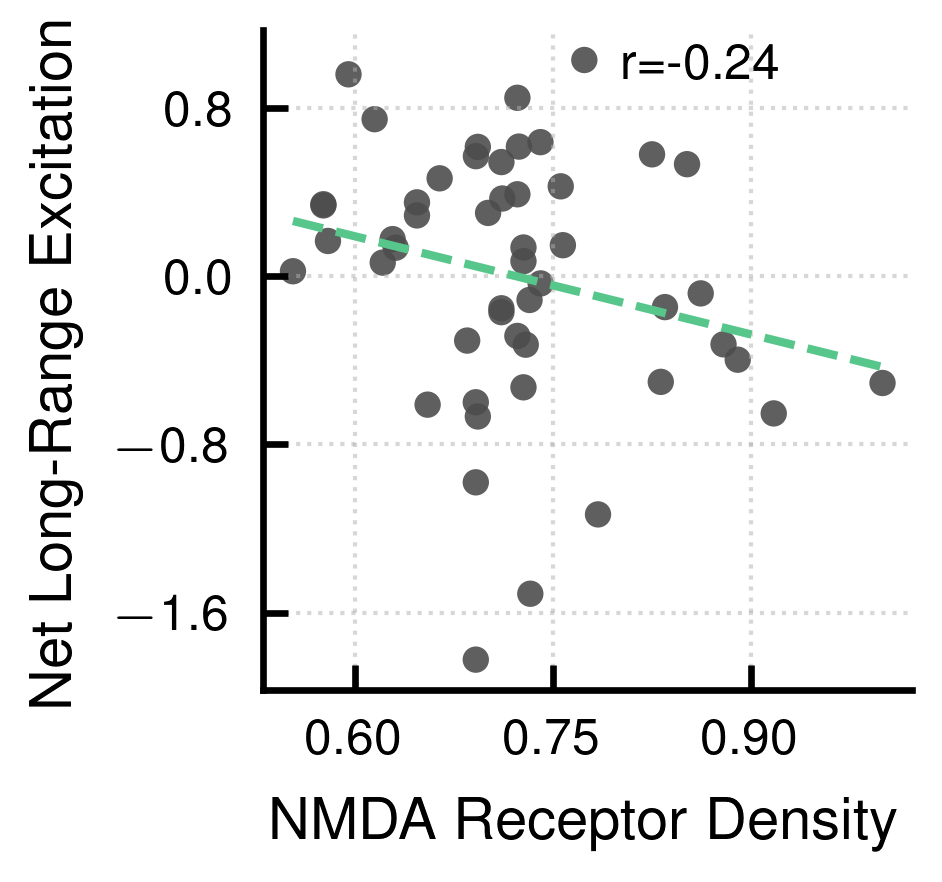

In [19]:
fig, ax = plt.subplots(figsize=(1.65, 1.55))
x = df_e_vs_i['nmda_rd'].to_numpy()
x = x / max(x)
y = df_e_vs_i['E_minus_I_receive'].to_numpy()
r, p = pearsonr(x, y)
print(f"NMDA vs net-E Pearson r = {r:.3f}, p = {p:.3g}")
ax.scatter(x, y, s=10, alpha=0.9, color='#4d4d4d', edgecolor='none')
slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color='#56c68a', linestyle='--', linewidth=1,
         label=f"y = {slope:.2f} x NMDA_rd + ({intercept:.2f})")
ax.set_xlabel('NMDA Receptor Density', )
ax.set_ylabel('Net Long-Range Excitation', )
ax.grid(True, linestyle=':', alpha=0.5)
ax = plt.gca()
from matplotlib.ticker import MaxNLocator
ax.minorticks_off()
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))
ax.grid(which='major', linestyle=':', alpha=0.5)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
frame.set_edgecolor('grey')
frame.set_linewidth(0.3)
plt.tight_layout()
ax.text(
    0.8, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.savefig('../results/long_rage_projections_strengths_schaefer100/long_range_E_minus_I_vs_nmda_rd.svg', dpi=1200, bbox_inches='tight')
plt.show()

## Clusters of excitation and inhibition receivers
### Visualize distribution of hierarchy and NMDa receptor density between the two population clusters: excitation receivers and inhibition receivers

Hierarchy p-value: 1.1862163042058839e-12
NMDA p-value: 0.001317126950239994


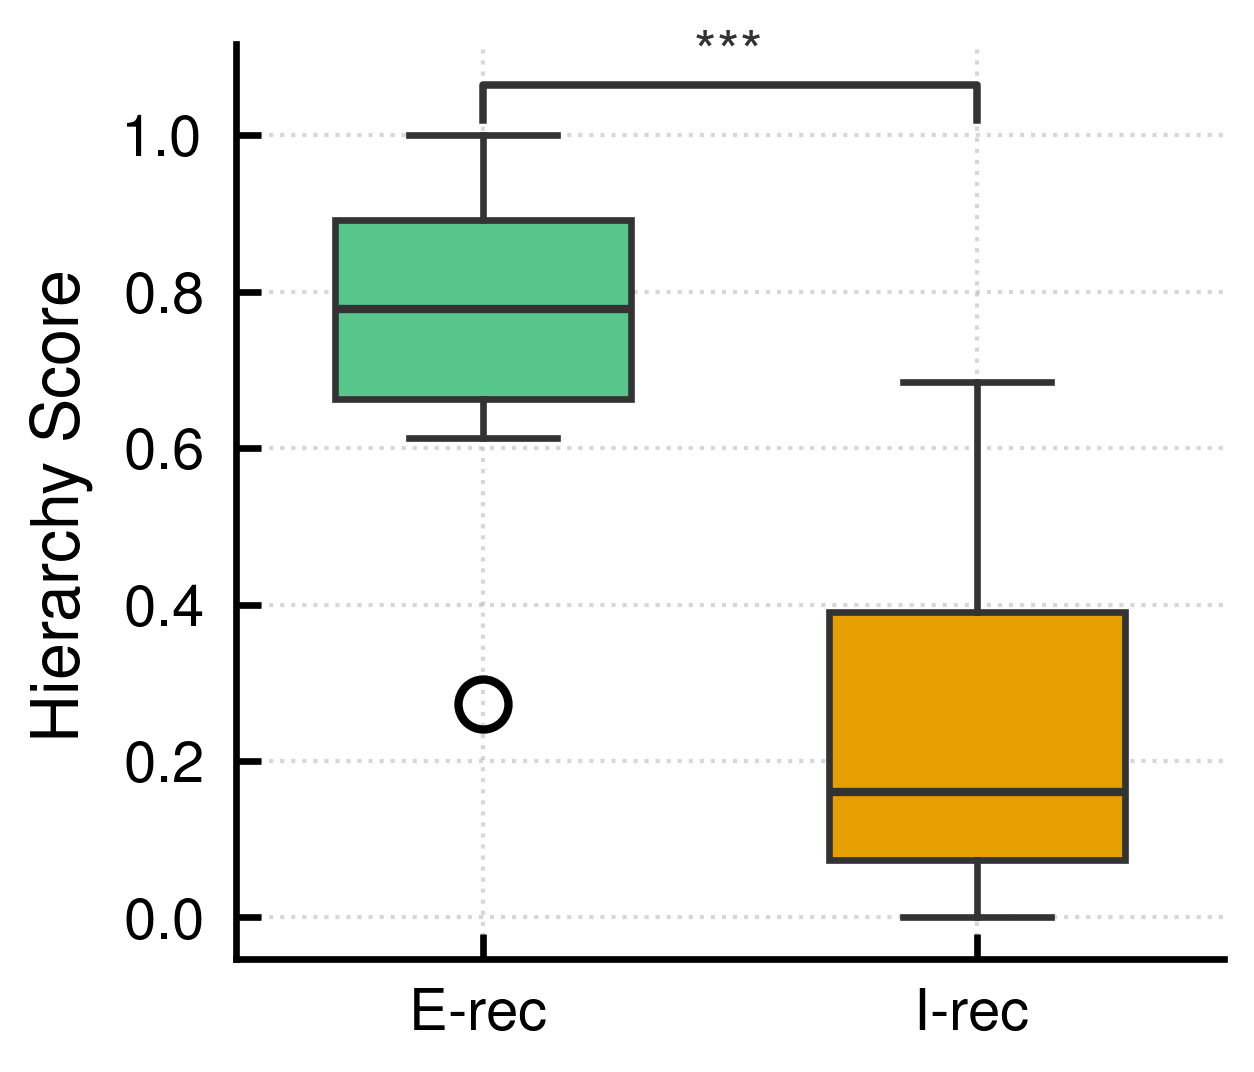

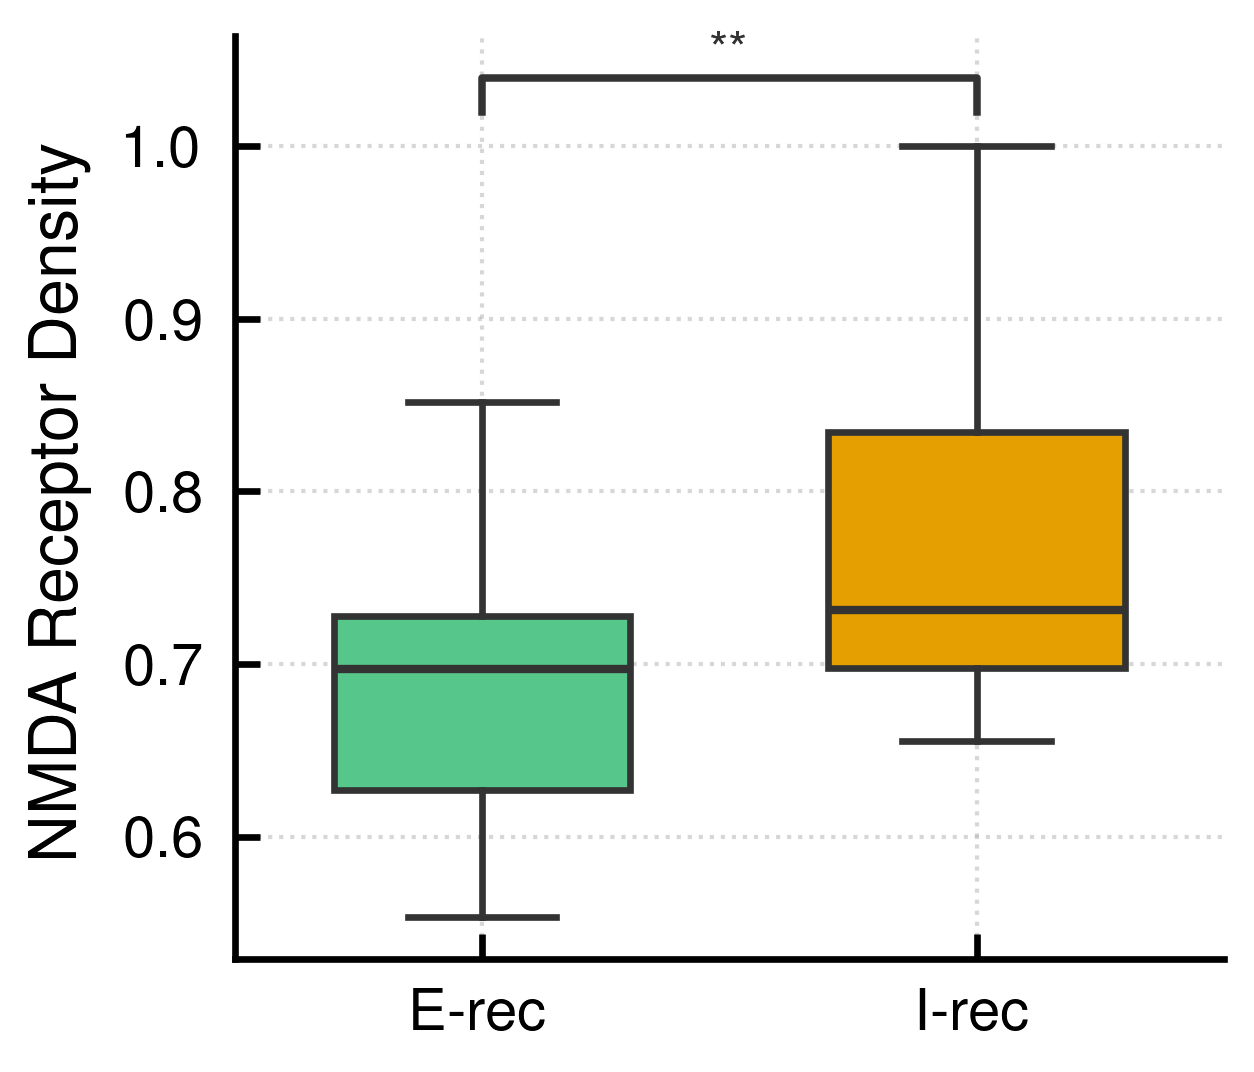

In [20]:
from scipy import stats
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})
def annotate_significance(ax, x1, x2, y, p, fontsize=6):
    if p < 0.001:
        text = '***'
    elif p < 0.01:
        text = '**'
    elif p < 0.05:
        text = '*'
    else:
        text = 'n.s.'

    y0, y1 = ax.get_ylim()
    barh = 0.04 * (y1 - y0) # 4% of axis range

    ax.plot([x1, x1, x2, x2],
            [y, y+barh, y+barh, y],
            lw=0.9, color='#333333')
    ax.text((x1 + x2)/2, y + barh*1.05, text,
            ha='center', va='bottom', fontsize=fontsize, color='#333333')

nmda_excitation_receivers = df_e_vs_i[df_e_vs_i['node_type'] == 'Excitation-Receivers']['nmda_rd'].to_numpy()
hierarchy_excitation_receivers = df_e_vs_i[df_e_vs_i['node_type'] == 'Excitation-Receivers']['hierarchy'].to_numpy()
nmda_inhibition_receivers = df_e_vs_i[df_e_vs_i['node_type'] == 'Inhibition-Receivers']['nmda_rd'].to_numpy()
hierarchy_inhibition_receivers = df_e_vs_i[df_e_vs_i['node_type'] == 'Inhibition-Receivers']['hierarchy'].to_numpy()

nmda_all = np.concatenate([nmda_excitation_receivers, nmda_inhibition_receivers])
nmda_max = nmda_all.max()
nmda_excitation_receivers = nmda_excitation_receivers / nmda_max
nmda_inhibition_receivers = nmda_inhibition_receivers / nmda_max

# Welch t-tests
_, p_hier = stats.ttest_ind(hierarchy_excitation_receivers, hierarchy_inhibition_receivers, equal_var=False)
_, p_nmda = stats.ttest_ind(nmda_excitation_receivers, nmda_inhibition_receivers, equal_var=False)
print('Hierarchy p-value:', p_hier)
print('NMDA p-value:', p_nmda)


fig, ax = plt.subplots(figsize=(2.2, 1.9))
clusters = ['E-rec', 'I-rec']
data_h = [hierarchy_excitation_receivers, hierarchy_inhibition_receivers]
bp = ax.boxplot(
    data_h,
    tick_labels=clusters,
    patch_artist=True,
    widths=0.6,
    medianprops=dict(color='#333333', linewidth=1.0),
    whiskerprops=dict(color='#333333', linewidth=0.8),
    capprops=dict(color='#333333', linewidth=0.8),
    boxprops=dict(edgecolor='#333333', linewidth=0.8)
)

for patch, c in zip(bp['boxes'], ['#56c68a', '#e69f00']):
    patch.set_facecolor(c)
ax.set_ylabel('Hierarchy Score', )
ax.minorticks_off()
ax.grid(which='major', linestyle=':', alpha=0.5)
ymax = max(np.max(hierarchy_excitation_receivers), np.max(hierarchy_inhibition_receivers))
annotate_significance(ax, 1, 2, y=ymax*1.02, p=p_hier, fontsize=7)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
plt.tight_layout()
plt.savefig('../results/long_rage_projections_strengths_schaefer100/hierarchy_by_dominant_node_type.svg', bbox_inches='tight')
plt.show()


fig, ax = plt.subplots(figsize=(2.2, 1.9))
data_nmda = [nmda_excitation_receivers, nmda_inhibition_receivers]
bp = ax.boxplot(
    data_nmda,
    tick_labels=clusters,
    patch_artist=True,
    widths=0.6,
    medianprops=dict(color='#333333', linewidth=1.0),
    whiskerprops=dict(color='#333333', linewidth=0.8),
    capprops=dict(color='#333333', linewidth=0.8),
    boxprops=dict(edgecolor='#333333', linewidth=0.8)
)

for patch, c in zip(bp['boxes'], ['#56c68a', '#e69f00']):
    patch.set_facecolor(c)
ax.set_ylabel('NMDA Receptor Density', )
ax.minorticks_off()
ax.grid(which='major', linestyle=':', alpha=0.5)
ymax = max(np.max(nmda_excitation_receivers), np.max(nmda_inhibition_receivers))
annotate_significance(ax, 1, 2, y=ymax*1.02, p=p_nmda)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
plt.tight_layout()
plt.savefig('../results/long_rage_projections_strengths_schaefer100/nmda_by_Dominant_Node_Type.svg', bbox_inches='tight')
plt.show()